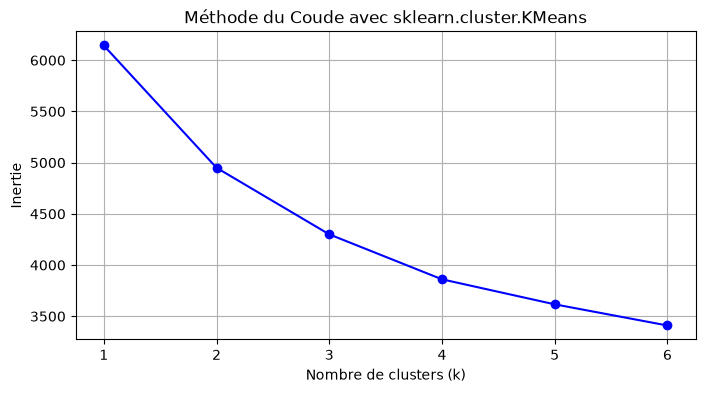

Moyennes cliniques par cluster :
            Glucose        BMI  DiabetesPedigreeFunction        Age
Cluster                                                            
0        137.454734  35.247936                  0.503754  40.845938
1        108.087640  29.937613                  0.437805  26.569343
✅ Clustering avec Scikit-Learn réussi et sauvegardé !


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Chargement des données
df_capped = pd.read_csv('../data/processed/df_capped.csv')
df_scaled = pd.read_csv('../data/processed/df_scaled.csv')

# 2. Recherche du k optimal (Méthode du Coude & Silhouette)
inertias = []
silhouettes = []
k_range = range(1, 7)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertias.append(kmeans.inertia_)
    # silhouettes.append(silhouette_score(df_scaled, kmeans.labels_))

# Visualisation du Coude
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertias, 'bo-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Inertie')
plt.title('Méthode du Coude avec sklearn.cluster.KMeans')
plt.grid(True)
plt.show()

# 3. Entraînement final avec k = 2
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
df_capped['Cluster'] = kmeans_final.fit_predict(df_scaled)

# 4. Analyse des clusters et création de la cible risk_category
cluster_means = df_capped.groupby('Cluster').mean()
print("Moyennes cliniques par cluster :")
print(cluster_means[['Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age']])

high_risk_cluster = cluster_means[
    (cluster_means['Glucose'] > 126) | 
    (cluster_means['BMI'] > 30) | 
    (cluster_means['DiabetesPedigreeFunction'] > 0.5)
].index[0]

df_capped['risk_category'] = (df_capped['Cluster'] == high_risk_cluster).astype(int)

# 5. Sauvegarde pour la classification
df_capped.to_csv('../data/processed/df_classified_target.csv', index=False)
print("✅ Clustering avec Scikit-Learn réussi et sauvegardé !")